In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("student_spending (1).csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1000
Number of Columns: 18


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Unnamed: 0                1000 non-null   int64
 1   age                       1000 non-null   int64
 2   gender                    1000 non-null   str  
 3   year_in_school            1000 non-null   str  
 4   major                     1000 non-null   str  
 5   monthly_income            1000 non-null   int64
 6   financial_aid             1000 non-null   int64
 7   tuition                   1000 non-null   int64
 8   housing                   1000 non-null   int64
 9   food                      1000 non-null   int64
 10  transportation            1000 non-null   int64
 11  books_supplies            1000 non-null   int64
 12  entertainment             1000 non-null   int64
 13  personal_care             1000 non-null   int64
 14  technology                1000 non-null   int64
 15 

In [6]:
df.describe()

,Unnamed: 0,age,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,21.675000,1020.650000,504.771000,4520.395000,696.00600,252.642000,124.63700,174.761000,84.814000,60.699000,178.304000,114.310000,108.910000
std,288.819436,2.322664,293.841161,287.092575,860.657944,171.21862,86.949606,43.55799,72.404518,37.970451,22.898007,71.744441,49.591544,52.412221
min,0.000000,18.000000,501.000000,0.000000,3003.000000,401.00000,100.000000,50.00000,50.000000,20.000000,20.000000,50.000000,30.000000,20.000000
25%,249.750000,20.000000,770.750000,261.000000,3779.750000,538.75000,175.000000,88.00000,112.000000,54.000000,41.000000,114.000000,73.000000,63.750000
50%,499.500000,22.000000,1021.000000,513.000000,4547.500000,704.50000,255.000000,123.00000,175.000000,86.000000,62.000000,178.000000,115.000000,110.000000
75%,749.250000,24.000000,1288.250000,751.500000,5285.000000,837.25000,330.000000,162.25000,238.000000,116.000000,80.000000,241.000000,158.000000,153.000000
max,999.000000,25.000000,1500.000000,1000.000000,6000.000000,1000.00000,400.000000,200.00000,300.000000,150.000000,100.000000,300.000000,200.000000,200.000000


In [7]:
print(df.isnull().sum())

Unnamed: 0                  0
age                         0
gender                      0
year_in_school              0
major                       0
monthly_income              0
financial_aid               0
tuition                     0
housing                     0
food                        0
transportation              0
books_supplies              0
entertainment               0
personal_care               0
technology                  0
health_wellness             0
miscellaneous               0
preferred_payment_method    0
dtype: int64


In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
df = df.drop(columns=['Unnamed: 0'])

print("Unnecessary column removed!")
print(df.shape)

Unnecessary column removed!
(1000, 17)


In [10]:
expense_columns = [
    'tuition',
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous'
]

df['total_expenses'] = df[expense_columns].sum(axis=1)

print("Total expenses calculated successfully!")

df[['monthly_income', 'total_expenses']].head()

Total expenses calculated successfully!


,monthly_income,total_expenses
0,958,7707
1,1006,6756
2,734,4810
3,617,6665
4,810,5828


In [11]:
print("Average Student Expenses:", df['total_expenses'].mean())

print("Minimum Expenses:", df['total_expenses'].min())

print("Maximum Expenses:", df['total_expenses'].max())

Average Student Expenses: 6315.478
Minimum Expenses: 4453
Maximum Expenses: 8266


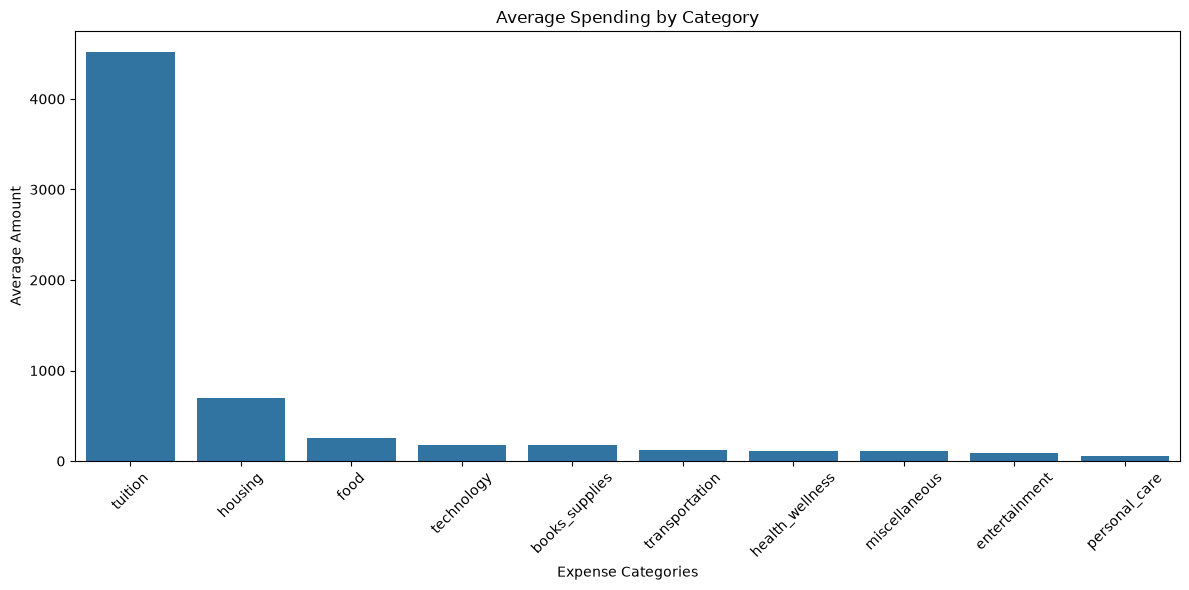

In [12]:
category_spending = df[expense_columns].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(x=category_spending.index, y=category_spending.values)

plt.title("Average Spending by Category")
plt.xlabel("Expense Categories")
plt.ylabel("Average Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

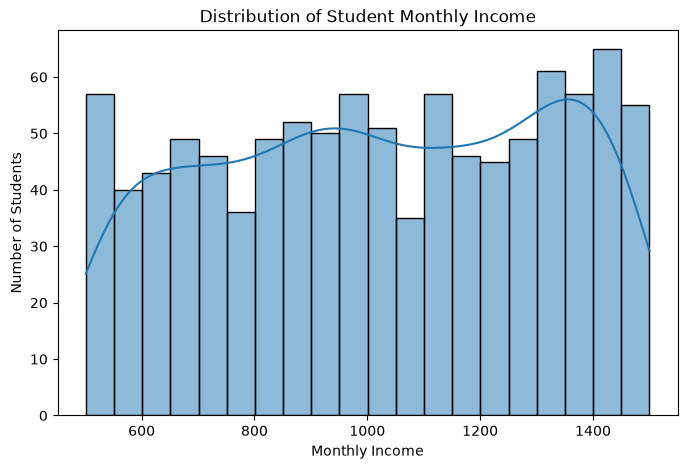

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df['monthly_income'], bins=20, kde=True)

plt.title("Distribution of Student Monthly Income")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Students")

plt.show()

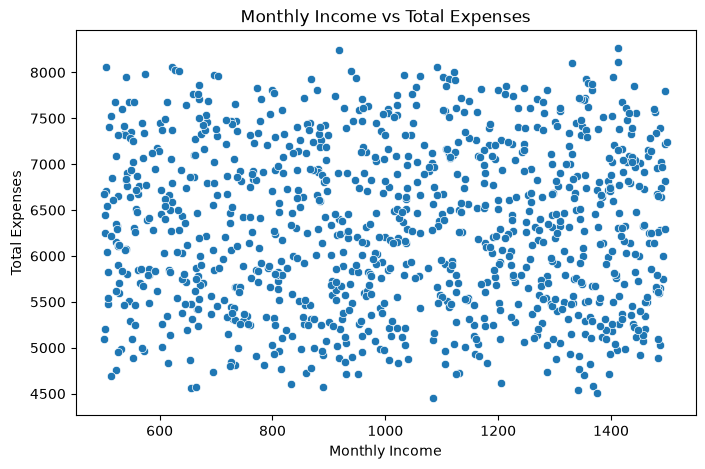

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='monthly_income',
    y='total_expenses',
    data=df
)

plt.title("Monthly Income vs Total Expenses")
plt.xlabel("Monthly Income")
plt.ylabel("Total Expenses")

plt.show()

In [15]:
correlation = df['monthly_income'].corr(df['total_expenses'])

print("Correlation:", correlation)

Correlation: 0.00026374956122391757


In [16]:
df.dtypes

age                         int64
gender                        str
year_in_school                str
major                         str
monthly_income              int64
financial_aid               int64
tuition                     int64
housing                     int64
food                        int64
transportation              int64
books_supplies              int64
entertainment               int64
personal_care               int64
technology                  int64
health_wellness             int64
miscellaneous               int64
preferred_payment_method      str
total_expenses              int64
dtype: object

In [17]:
df = pd.get_dummies(df, drop_first=True)

print("Categorical data converted successfully!")

Categorical data converted successfully!


In [18]:
X = df.drop(columns=['total_expenses'])
y = df['total_expenses']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 24)
Target shape: (1000,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 24)
Testing data: (200, 24)


In [20]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [21]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [22]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [23]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(random_state=42)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [24]:
models = {
    'Linear Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions,
    'Gradient Boosting': gb_predictions
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2 Score']
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,9.868018e-13,1.410343e-24,1.187579e-12,1.000000
1,Decision Tree,1.782350e+02,5.163940e+04,2.272431e+02,0.932962
2,Random Forest,1.114789e+02,1.855485e+04,1.362162e+02,0.975912
3,Gradient Boosting,6.655522e+01,6.812327e+03,8.253682e+01,0.991156


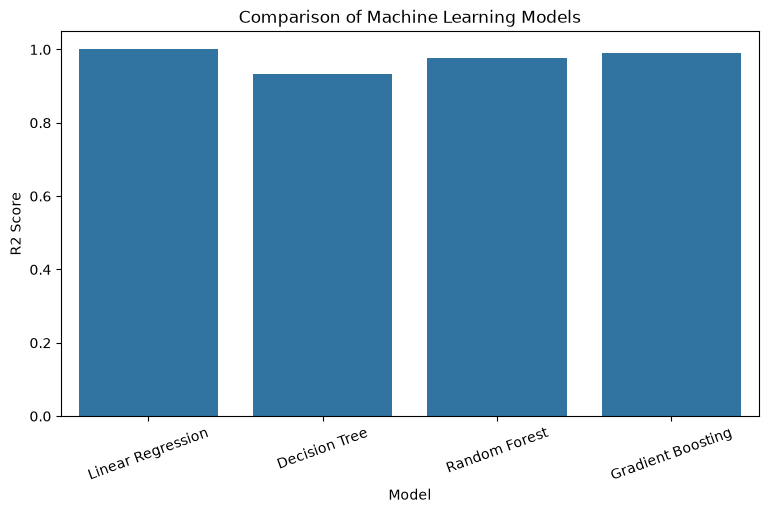

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x='Model',
    y='R2 Score',
    data=results_df
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)

plt.show()

In [26]:
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(), 'Model'
]

print("Best Performing Model:", best_model_name)

Best Performing Model: Linear Regression


In [27]:
import joblib

model_dict = {
    'Linear Regression': lr_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

best_model = model_dict[best_model_name]

joblib.dump(best_model, 'best_student_spending_model.pkl')

print("Best model saved successfully!")

Best model saved successfully!


In [28]:
X = df.drop(columns=expense_columns + ['total_expenses'])
y = df['total_expenses']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1000, 14)
Target: (1000,)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


In [30]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2 Score']
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,765.021827,7.947080e+05,891.463975,-0.031692
1,Decision Tree,976.885000,1.455347e+06,1206.377816,-0.889335
2,Random Forest,754.092000,8.126710e+05,901.482679,-0.055011
3,Gradient Boosting,768.888042,8.304625e+05,911.297160,-0.078108


In [31]:
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

Best Performing Model: Linear Regression


In [32]:
import joblib

joblib.dump(best_model, 'best_student_spending_model.pkl')

print("Final model saved successfully!")

Final model saved successfully!


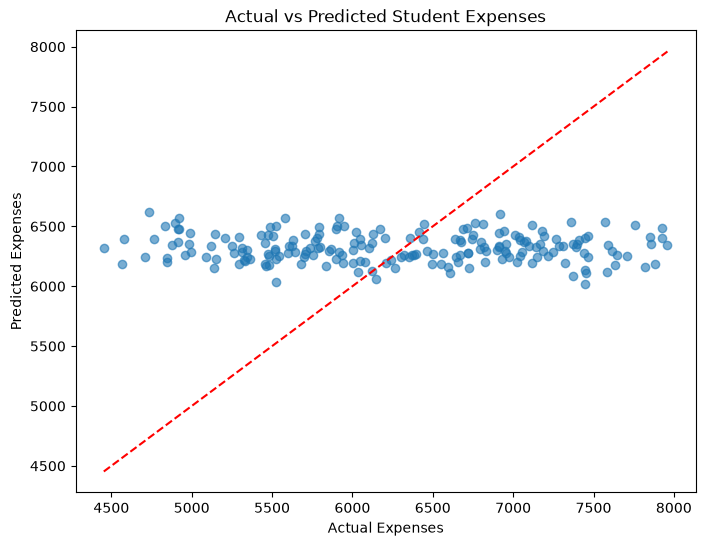

In [33]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Expenses")
plt.ylabel("Predicted Expenses")
plt.title("Actual vs Predicted Student Expenses")

plt.show()

In [34]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
3,gender_Male,0.007357
0,age,0.004235
11,major_Psychology,0.003516
8,major_Computer Science,0.002842
12,preferred_payment_method_Credit/Debit Card,0.002438
7,year_in_school_Sophomore,0.002149
6,year_in_school_Senior,0.001941
2,financial_aid,0.000689
9,major_Economics,0.000440
1,monthly_income,-0.000252


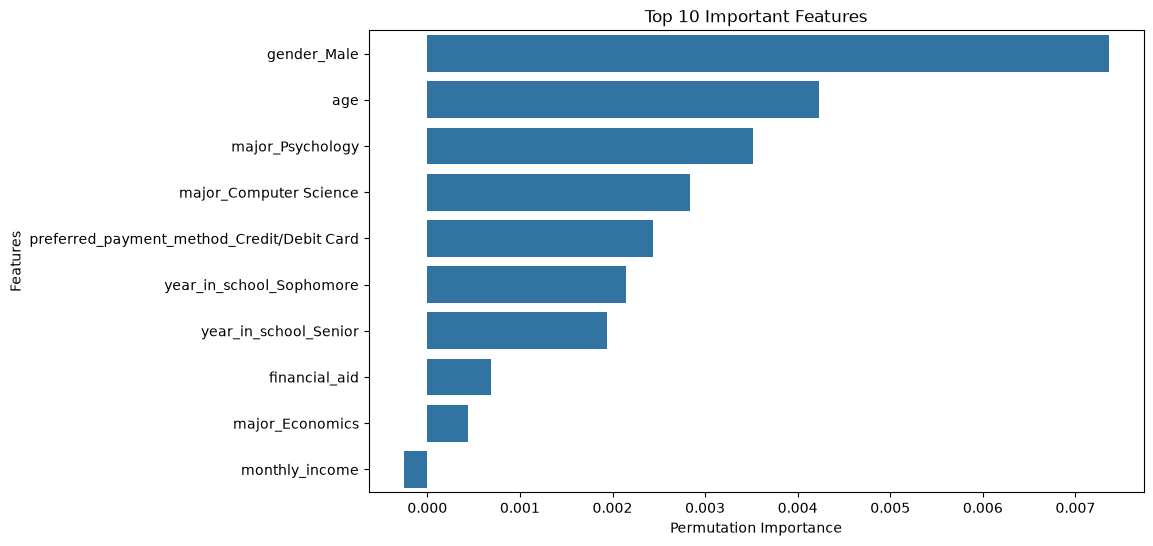

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")

plt.show()

In [36]:
sample_student = X_test.iloc[[0]]

predicted_expense = best_model.predict(sample_student)

actual_expense = y_test.iloc[0]

print("Predicted Expenses:", round(predicted_expense[0], 2))
print("Actual Expenses:", actual_expense)

Predicted Expenses: 6316.63
Actual Expenses: 5733


In [37]:
print("Final Model:", best_model_name)

print("MAE:", mean_absolute_error(y_test, best_predictions))

print("MSE:", mean_squared_error(y_test, best_predictions))

print("RMSE:", np.sqrt(mean_squared_error(y_test, best_predictions)))

print("R2 Score:", r2_score(y_test, best_predictions))

Final Model: Linear Regression
MAE: 765.0218271194243
MSE: 794708.0195947852
RMSE: 891.4639754890745
R2 Score: -0.03169156065408596


In [38]:
import joblib

joblib.dump(best_model, 'best_student_spending_model.pkl')

results_df.to_csv('model_comparison.csv', index=False)

importance_df.to_csv('feature_importance.csv', index=False)

print("All project files saved successfully!")

All project files saved successfully!
